# 07 — Évaluation finale : dans le temps, avec la distance, en France

> **La réponse.** 
**Oui : corrigé par un modèle appris sur d'autres stations, un capteur SDS011 en bon état passe les cibles de l'EPA
dans 80 % des cas en horaire et 85 % en journalier (contre 25 % et 39 % sans correction), et cela tient jusqu'à 3 km
d'une station (70 à 82 % selon la distance ; 81 à 92 % quand le capteur a au moins 3 voisins citoyens). La vraie
limite n'est pas la distance mais la densité du réseau citoyen et le temps : sans voisins, moins d'un capteur sur deux
passe, et un modèle appris sur une année perd 15 points l'année suivante, il faut donc le réapprendre chaque année.
Le modèle allemand ne se transpose pas tel quel en France (23 % des capteurs sains en horaire, 35 % en journalier),
où 61 % des heures n'ont pas de voisins : il y faut une calibration locale.**


**But de ce notebook.** Le modèle retenu à l'étape 6 (LightGBM en µg/m³, 45 variables, contrainte monotone, réglages
Optuna) a été évalué sur des **stations jamais vues**, mais sur les deux années mélangées, en Allemagne et à moins de
1,5 km. Ici, on le sort de ces conditions, une à une :

1. **dans le temps** : appris sur 2024, testé sur 2025 ;
2. **avec la distance** : capteurs jusqu'à 3 km de la station de référence ;
3. **dans un autre pays** : la France, sans aucun réajustement ;

puis on découpe les résultats (type de station, méthode de mesure, saison, humidité), on compare à la littérature, on
corrige la couverture de l'intervalle et on fait le point sur le score de santé.

Comme au notebook 06, tout vient des runs MLflow (`python -m aircalib train --study temporal | distance | france |
breakdowns | conformal`) ; ce notebook ne réentraîne rien. Chaque tableau donne les **paires saines** et **toutes
paires**, et les heures **avec** et **sans** voisins citoyens. Le « % EPA » est la part des paires qui passent les quatre
cibles de l'EPA ($R^2 \ge 0{,}70$, pente $1 \pm 0{,}35$, ordonnée $\pm 5$ µg/m³, RMSE ≤ 7 µg/m³), calculées paire par paire
sur ses heures (au moins 500) ou ses jours complets (au moins 30) de la tranche considérée.

## 0. Préparation

**Ce qu'on fait.** On charge la configuration et deux fonctions de lecture : `run_table` (une table enregistrée par un
run MLflow) et `compact` (horaire et journalier côte à côte, une ligne par paires × heures).
**Pourquoi.** Les mêmes colonnes dans tous les tableaux : RMSE, $R^2$, pente, ordonnée, nombre de paires notées et % EPA
en horaire ; RMSE et % EPA en journalier.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from aircalib.config import get_settings
from aircalib.evaluation.health import confusion, threshold_cv
from aircalib.models import results

settings = get_settings()
FIG_DIR = settings.paths.reports_dir / "figures"
pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_hide_dataframe_shape(True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def summary(parent, run):
    return results.compact(results.run_table(settings, parent, run, "summary"))


def sliced(parent, run, name):
    return results.compact(results.run_table(settings, parent, run, f"slices_{name}"), [name])


def tag(frame, **labels):
    return frame.with_columns(**{k: pl.lit(v) for k, v in labels.items()}).select(
        *labels, pl.exclude(*labels)
    )

## 1. La référence de l'étape 6, et la vérification qui l'a précédée

**Ce qu'on fait.** On rappelle le chiffre de référence : 5 plis par station, deux années mélangées, Allemagne, ≤ 1,5 km.
On montre aussi la vérification demandée avant l'étape 7 : le modèle retenu faisait un peu moins bien que l'échelon 3
sur « toutes paires ». Partant de l'échelon 3, chacun des trois changements est appliqué seul, puis les trois ensemble
(réglages par défaut, volume complet).
**Pourquoi.** Savoir lequel des changements coûte sur les capteurs abîmés, et décider en connaissance de cause.

In [2]:
reference = summary("modele_final", "final_reglages_optuna")
reference

paires,voisins,heures,rmse_h,r2_h,pente_h,ordonnee_h,paires_notees,epa_h,rmse_j,epa_j
str,str,i64,f64,f64,f64,f64,i64,f64,f64,f64
"""saines""","""toutes""",4674183,3.84,0.76,0.82,2.01,459,79.7,2.98,85.3
"""saines""","""avec_voisins""",3700818,3.39,0.81,0.86,1.66,375,88.3,2.56,92.0
"""saines""","""sans_voisins""",973365,5.21,0.55,0.65,3.3,133,42.1,4.24,58.6
"""toutes""","""toutes""",5558171,4.38,0.7,0.79,2.3,549,74.7,3.52,81.9
"""toutes""","""avec_voisins""",4365221,3.54,0.8,0.85,1.8,445,84.3,2.69,90.2
"""toutes""","""sans_voisins""",1192950,6.59,0.39,0.6,4.04,162,36.4,5.66,49.6


In [3]:
attribution = results.children(settings, "attribution_recul", "complet")
cols = {
    "rmse saines": "hourly_saines_rmse",
    "epa saines": "hourly_saines_pct_epa_all",
    "rmse toutes": "hourly_toutes_rmse",
    "epa toutes": "hourly_toutes_pct_epa_all",
    "rmse saines sans voisins": "hourly_saines_sans_voisins_rmse",
    "epa saines sans voisins": "hourly_saines_sans_voisins_pct_epa_all",
    "rmse toutes sans voisins": "hourly_toutes_sans_voisins_rmse",
    "epa toutes sans voisins": "hourly_toutes_sans_voisins_pct_epa_all",
}
attribution.select("run", **{k: pl.col(v).round(2) for k, v in cols.items()})

run,rmse saines,epa saines,rmse toutes,epa toutes,rmse saines sans voisins,epa saines sans voisins,rmse toutes sans voisins,epa toutes sans voisins
str,f64,f64,f64,f64,f64,f64,f64,f64
"""echelon_3""",3.95,76.69,4.3,72.5,5.24,44.36,6.18,38.27
"""cible_ugm3""",3.92,78.0,4.46,73.59,5.25,42.86,6.67,36.42
"""contrainte_monotone""",3.95,76.47,4.31,71.77,5.25,45.11,6.2,38.27
"""sans_sonde_locale""",3.97,76.47,4.33,72.13,5.3,44.36,6.23,38.89
"""trois_changements""",3.91,77.34,4.45,72.86,5.23,44.36,6.66,38.27


**Ce qu'on observe.** 
L'échelon 3 rejoue exactement le run de l'étape 6 (3,95 µg/m³ ; 76,7 %) : le calcul est déterministe.

- **Cible µg/m³** : elle seule cause le recul sur toutes paires (RMSE 4,30 → 4,46 ; sans voisins, 6,18 → 6,67). Elle
  apporte un peu sur les paires saines : 3,95 → 3,92 µg/m³, et 76,7 % → 78,0 % de paires EPA en horaire.
- **Contrainte monotone** : neutre.
- **Retrait de la sonde locale** : ±0,02 µg/m³, dans le bruit.

Règle fixée au départ : un changement est annulé s'il cause le recul **sans rien apporter** sur les paires saines. Ce
n'est pas le cas de la cible en µg/m³, donc **le modèle retenu est gardé**. Le produit vise les capteurs sains, et les
capteurs abîmés sont repérés par le score de santé. Limite : ce score ne repère qu'environ 56 % d'entre eux
(section 8).

## 2. Dans le temps : appris sur 2024, testé sur 2025

**Ce qu'on fait.** Trois façons d'apprendre sur 2024 (ou 2025) et de tester sur 2025, toutes avec un modèle physique
($a$, $\kappa$) réajusté sur les seules lignes d'entraînement :

- **(a) mêmes stations, futur** : un modèle appris sur toutes les paires saines de 2024, testé sur les heures 2025 des
  paires qui existaient en 2024. C'est le cas réaliste : on calibre un réseau une année, on l'utilise l'année suivante ;
- **(b) nouvelles stations, futur** : plis par station **et** 2024 → 2025 ;
- **(b0) témoin** : nouvelles stations, appris et testé sur 2025 (mêmes heures de test que b, même volume
  d'apprentissage d'environ un an, sans écart de temps).

Les références sont les prédictions hors pli du modèle final (deux années mélangées), restreintes aux mêmes heures 2025.
**Pourquoi.** L'écart **b − b0** isole le coût de l'année d'écart (la dérive), à volume d'apprentissage égal. L'écart
**b − référence** mêle dérive et moitié moins de données. Le cas **(a)** dit ce que gagne un client qui garde ses
stations.

In [4]:
temporal_runs = [
    ("référence, 5 plis, 2025", "reference_5_plis_2025"),
    ("b0 nouvelles stations, 2025 → 2025", "b0_nouvelles_stations_2025_vers_2025"),
    ("b nouvelles stations, 2024 → 2025", "b_nouvelles_stations_2024_vers_2025"),
    ("référence, mêmes paires, 2025", "reference_5_plis_2025_memes_paires"),
    ("a mêmes stations, 2024 → 2025", "a_memes_stations_2024_vers_2025"),
]
temporal = pl.concat([tag(summary("test_temporel", run), scénario=label) for label, run in temporal_runs])
temporal.filter(pl.col("paires") == "saines")

scénario,paires,voisins,heures,rmse_h,r2_h,pente_h,ordonnee_h,paires_notees,epa_h,rmse_j,epa_j
str,str,str,i64,f64,f64,f64,f64,i64,f64,f64,f64
"""référence, 5 plis, 2025""","""saines""","""toutes""",2204983,3.91,0.78,0.83,1.89,357,82.4,3.06,86.9
"""référence, 5 plis, 2025""","""saines""","""avec_voisins""",1740422,3.42,0.83,0.87,1.58,286,89.5,2.58,92.9
"""référence, 5 plis, 2025""","""saines""","""sans_voisins""",464561,5.34,0.6,0.68,2.99,95,51.6,4.44,65.1
"""b0 nouvelles stations, 2025 → …","""saines""","""toutes""",2204983,3.83,0.79,0.85,1.7,357,84.3,2.98,88.9
"""b0 nouvelles stations, 2025 → …","""saines""","""avec_voisins""",1740422,3.37,0.84,0.88,1.4,286,92.0,2.53,93.2
"""b0 nouvelles stations, 2025 → …","""saines""","""sans_voisins""",464561,5.21,0.62,0.71,2.78,95,55.8,4.28,69.8
"""b nouvelles stations, 2024 → 2…","""saines""","""toutes""",2204983,4.38,0.72,0.72,2.95,357,69.5,3.43,81.2
"""b nouvelles stations, 2024 → 2…","""saines""","""avec_voisins""",1740422,3.96,0.77,0.76,2.69,286,79.0,2.96,89.0
"""b nouvelles stations, 2024 → 2…","""saines""","""sans_voisins""",464561,5.7,0.54,0.58,3.89,95,38.9,4.8,52.3


In [5]:
temporal.filter(pl.col("paires") == "toutes")

scénario,paires,voisins,heures,rmse_h,r2_h,pente_h,ordonnee_h,paires_notees,epa_h,rmse_j,epa_j
str,str,str,i64,f64,f64,f64,f64,i64,f64,f64,f64
"""référence, 5 plis, 2025""","""toutes""","""toutes""",2635003,4.49,0.72,0.81,2.2,434,77.4,3.67,82.8
"""référence, 5 plis, 2025""","""toutes""","""avec_voisins""",2071609,3.59,0.82,0.86,1.74,346,86.1,2.75,90.6
"""référence, 5 plis, 2025""","""toutes""","""sans_voisins""",563394,6.83,0.43,0.62,3.83,116,43.1,5.97,55.7
"""b0 nouvelles stations, 2025 → …","""toutes""","""toutes""",2635003,4.53,0.72,0.82,2.03,434,79.0,3.72,84.5
"""b0 nouvelles stations, 2025 → …","""toutes""","""avec_voisins""",2071609,3.53,0.82,0.87,1.55,346,88.2,2.7,90.6
"""b0 nouvelles stations, 2025 → …","""toutes""","""sans_voisins""",563394,7.07,0.42,0.64,3.69,116,45.7,6.22,58.5
"""b nouvelles stations, 2024 → 2…","""toutes""","""toutes""",2635003,4.91,0.66,0.7,3.24,434,64.1,3.96,76.0
"""b nouvelles stations, 2024 → 2…","""toutes""","""avec_voisins""",2071609,4.1,0.76,0.75,2.82,346,74.3,3.12,84.7
"""b nouvelles stations, 2024 → 2…","""toutes""","""sans_voisins""",563394,7.13,0.35,0.52,4.7,116,31.9,6.18,43.4


**Croisement avec l'âge du capteur.** **Ce qu'on fait** : le même tableau découpé par âge du capteur à l'heure de la
mesure (paires saines, toutes heures). **Pourquoi** : si la dérive vient du vieillissement de l'optique, l'écart entre
(b) et (b0) devrait croître avec l'âge.

In [6]:
by_age = pl.concat(
    [
        tag(sliced("test_temporel", run, "age"), scénario=label)
        for label, run in temporal_runs
        if not label.startswith("référence, mêmes")
    ]
).filter((pl.col("paires") == "saines") & (pl.col("voisins") == "toutes"))
by_age.select("scénario", "age", "heures", "paires_notees", "rmse_h", "r2_h", "pente_h", "epa_h").pivot(
    on="scénario", index="age", values="rmse_h"
).sort("age")

age,"référence, 5 plis, 2025","b0 nouvelles stations, 2025 → 2025","b nouvelles stations, 2024 → 2025","a mêmes stations, 2024 → 2025"
str,f64,f64,f64,f64
"""0. < 1 ans""",3.83,4.01,4.12,4.39
"""1. 1–2 ans""",4.1,4.09,4.64,4.02
"""2. 2–3 ans""",4.87,4.64,5.28,4.34
"""3. 3–5 ans""",4.06,3.93,4.67,3.77
"""4. ≥ 5 ans""",3.74,3.65,4.19,3.51


In [7]:
by_age.pivot(on="scénario", index="age", values="epa_h").sort("age")

age,"référence, 5 plis, 2025","b0 nouvelles stations, 2025 → 2025","b nouvelles stations, 2024 → 2025","a mêmes stations, 2024 → 2025"
str,f64,f64,f64,f64
"""0. < 1 ans""",81.4,79.1,72.1,78.6
"""1. 1–2 ans""",70.7,70.7,61.0,64.9
"""2. 2–3 ans""",64.3,71.4,60.7,70.4
"""3. 3–5 ans""",72.7,79.2,62.3,75.3
"""4. ≥ 5 ans""",83.0,83.5,70.5,84.1


**Ce qu'on fait.** Biais moyen (prédiction − référence) mois par mois en 2025, paires saines, pour (b) et son témoin (b0).
**Pourquoi.** Distinguer une dérive lente (un biais qui grandit au fil de 2025) d'une relation capteur → référence qui
change d'une année à l'autre selon les épisodes de pollution.

In [8]:
def predictions(parent, run):
    runs = results.children(settings, parent, "complet")
    run_id = runs.filter(pl.col("run") == run)["run_id"][0]
    return pl.read_parquet(results.artifact(settings, run_id, "oof_predictions.parquet"))


monthly = []
for label, run in temporal_runs[1:3]:
    part = predictions("test_temporel", run).filter(pl.col("sane_pair"))
    monthly.append(
        part.group_by(mois=pl.col("hour").dt.month())
        .agg(
            biais=(pl.col("prediction") - pl.col("reference")).mean().round(2),
            référence=pl.col("reference").mean().round(1),
        )
        .with_columns(scénario=pl.lit(label))
    )
monthly = pl.concat(monthly)
monthly.pivot(on="scénario", index="mois", values="biais").join(
    monthly.select("mois", "référence").unique(), on="mois"
).sort("mois")

mois,"b0 nouvelles stations, 2025 → 2025","b nouvelles stations, 2024 → 2025",référence
i8,f32,f32,f32
1,0.36,0.24,10.6
2,0.17,-1.71,19.700001
3,0.16,-0.44,17.6
4,0.27,1.09,8.9
5,0.2,0.71,6.5
6,0.18,1.45,7.7
7,0.17,0.89,6.4
8,0.07,0.05,7.6
9,0.19,0.54,5.8


**Ce qu'on observe.** 
Chiffres sur les paires saines, en horaire / journalier.

- **Référence** (5 plis, deux années mélangées, heures 2025) : RMSE 3,91 ; **82,4 % / 86,9 %**.
- **(b0) nouvelles stations, 2025 → 2025** : 3,91 → 3,83 ; 84,3 % / 88,9 %. Un an d'apprentissage suffit : le volume
  n'est pas le problème.
- **(b) nouvelles stations, 2024 → 2025** : RMSE **4,38** ; **69,5 % / 81,2 %**. Le **coût de l'année d'écart**
  (b − b0) est de **+0,55 µg/m³ (+14 %)**, **−15 points** en horaire et −8 en journalier. La pente tombe de 0,85 à
  0,72 et l'ordonnée monte de 1,7 à 2,95 : le modèle de 2024 réagit trop peu aux variations de 2025.
- **(a) mêmes stations, 2024 → 2025** : RMSE 3,69, meilleur que la référence sur les mêmes paires (3,93), et
  **92,1 %** des paires passent en journalier contre 87,1 %. En horaire, 82,0 % contre 82,7 % : la pente (0,74)
  souffre du même écart d'un an. Connaître le capteur aide surtout sans voisins : 4,52 µg/m³ et 60 % de paires EPA,
  contre 5,38 et 52,5 %.
- **Âge du capteur** : le coût de l'année d'écart (b − b0, RMSE) vaut +0,11 sous 1 an, puis +0,55, +0,64, +0,74 et
  +0,54 µg/m³ pour 1–2, 2–3, 3–5 et ≥ 5 ans. Il est faible pour les capteurs neufs et plus fort au-delà, sans
  croître régulièrement. C'est compatible avec un vieillissement de l'optique (poussière dans la chambre), mais pas
  une preuve.
- **Biais par mois** : le témoin (b0) garde un biais stable, entre +0,1 et +0,4 µg/m³. Le modèle de 2024
  **comprime** les valeurs de 2025 : il surestime les mois propres (juin : +1,45 µg/m³ pour une référence de 7,7) et
  sous-estime les mois pollués (février : −1,7 pour 19,7). C'est la pente de 0,72 vue mois par mois. La relation
  capteur → référence change d'une année à l'autre, selon les épisodes et la composition de l'aérosol ; un modèle appris
  sur une seule année n'en voit qu'une partie.
- **Conséquence produit** : **réapprendre le modèle chaque année** sur les données validées des stations (EEA, publiées
  chaque année), ou avec plusieurs années d'historique.

## 3. Avec la distance : jusqu'à quelle distance d'une station la correction tient-elle ?

**Ce qu'on fait.** Protocole inscrit au plan : pour chaque pli, toutes les paires des stations du pli (≤ 1,5 km **et**
1,5–3 km) sont exclues de l'entraînement ; le modèle apprend sur les paires ≤ 1,5 km des **autres** stations, puis
prédit toutes les paires du pli, bande par bande. Le « capteur brut » est donné sur les mêmes heures.
**Pourquoi.** C'est la question business. Attention à ce que mesure la distance : un capteur à 2,5 km mesure un air
**différent** de celui de la station ; l'« erreur » mêle alors l'erreur du capteur corrigé et la différence réelle
d'air entre les deux sites. C'est exactement ce que subit un client qui utilise la station la plus proche comme
référence.

In [9]:
dist_after = tag(sliced("test_distance", "modele_retenu", "distance"), modèle="corrigé")
dist_before = tag(sliced("test_distance", "capteur_brut", "distance"), modèle="brut")
distance_table = pl.concat([dist_before, dist_after])
distance_table.filter(pl.col("voisins") == "toutes").sort("paires", "distance", "modèle")

modèle,distance,paires,voisins,heures,rmse_h,r2_h,pente_h,ordonnee_h,paires_notees,epa_h,rmse_j,epa_j
str,str,str,str,i64,f64,f64,f64,f64,i64,f64,f64,f64
"""brut""","""0. < 0.5 km""","""saines""","""toutes""",1188823,8.53,0.31,0.64,-0.14,115,27.0,7.24,36.9
"""corrigé""","""0. < 0.5 km""","""saines""","""toutes""",1188823,3.49,0.8,0.87,1.64,115,81.7,2.73,88.3
"""brut""","""1. 0.5–1 km""","""saines""","""toutes""",1599648,14.49,0.09,0.58,1.01,162,26.5,11.14,38.6
"""corrigé""","""1. 0.5–1 km""","""saines""","""toutes""",1599648,4.0,0.73,0.79,2.21,162,80.2,3.1,86.1
"""brut""","""2. 1–1.5 km""","""saines""","""toutes""",1885712,8.81,0.29,0.63,0.34,182,22.0,7.84,40.8
"""corrigé""","""2. 1–1.5 km""","""saines""","""toutes""",1885712,3.91,0.75,0.81,2.06,182,78.0,3.02,82.8
"""brut""","""3. 1.5–2 km""","""saines""","""toutes""",2099252,8.4,0.31,0.63,0.14,199,23.1,7.28,40.4
"""corrigé""","""3. 1.5–2 km""","""saines""","""toutes""",2099252,3.82,0.75,0.81,2.02,199,80.4,3.0,88.1
"""brut""","""4. ≥ 2 km""","""saines""","""toutes""",3897143,8.79,0.27,0.59,0.51,371,22.6,7.89,35.5


In [10]:
dist_after.filter(pl.col("voisins") != "toutes").select(
    "distance", "paires", "voisins", "heures", "paires_notees", "rmse_h", "r2_h", "epa_h", "epa_j"
)

distance,paires,voisins,heures,paires_notees,rmse_h,r2_h,epa_h,epa_j
str,str,str,i64,i64,f64,f64,f64,f64
"""0. < 0.5 km""","""saines""","""avec_voisins""",1009735,103,3.28,0.82,87.4,90.9
"""0. < 0.5 km""","""saines""","""sans_voisins""",179088,24,4.53,0.65,50.0,66.7
"""0. < 0.5 km""","""toutes""","""avec_voisins""",1125777,113,3.36,0.82,88.5,91.7
"""0. < 0.5 km""","""toutes""","""sans_voisins""",179378,24,4.53,0.65,50.0,66.7
"""1. 0.5–1 km""","""saines""","""avec_voisins""",1201814,130,3.18,0.83,91.5,95.2
"""1. 0.5–1 km""","""saines""","""sans_voisins""",397834,50,5.82,0.49,40.0,60.0
"""1. 0.5–1 km""","""toutes""","""avec_voisins""",1458065,159,3.32,0.81,85.5,92.2
"""1. 0.5–1 km""","""toutes""","""sans_voisins""",544134,69,7.81,0.28,33.3,49.2
"""2. 1–1.5 km""","""saines""","""avec_voisins""",1489269,142,3.63,0.79,85.9,89.8


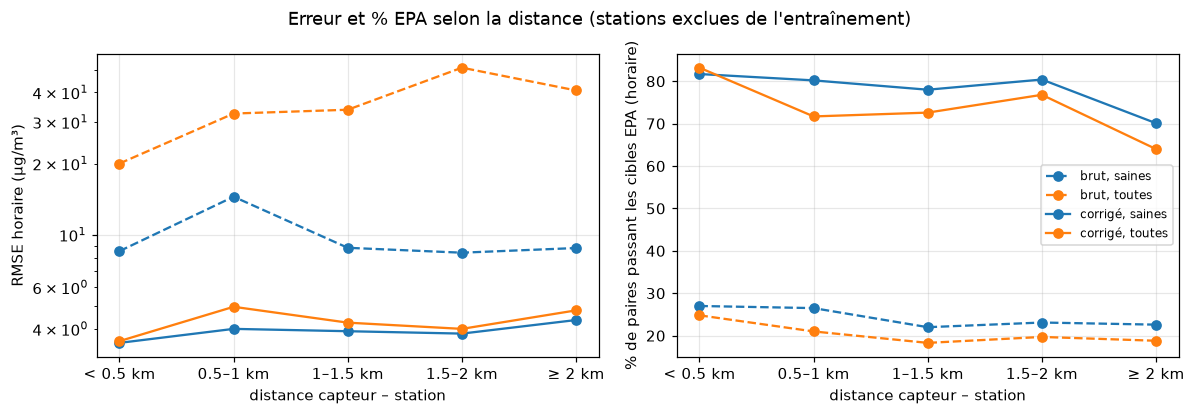

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for (label, frame), style in zip((("brut", dist_before), ("corrigé", dist_after)), ("--", "-"), strict=True):
    for subset, colour in (("saines", "tab:blue"), ("toutes", "tab:orange")):
        part = frame.filter((pl.col("paires") == subset) & (pl.col("voisins") == "toutes")).sort("distance")
        names = [d.split(". ")[1] for d in part["distance"]]
        axes[0].plot(names, part["rmse_h"], style, color=colour, marker="o", label=f"{label}, {subset}")
        axes[1].plot(names, part["epa_h"], style, color=colour, marker="o", label=f"{label}, {subset}")
axes[0].set_ylabel("RMSE horaire (µg/m³)")
axes[1].set_ylabel("% de paires passant les cibles EPA (horaire)")
for ax in axes:
    ax.set_xlabel("distance capteur – station")
axes[0].set_yscale("log")
axes[1].legend(fontsize=8)
fig.suptitle("Erreur et % EPA selon la distance (stations exclues de l'entraînement)")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_distance.png")

**Ce qu'on observe.** 
Chiffres sur les paires saines, en horaire / journalier, pour le capteur corrigé.

- **La distance compte peu jusqu'à 3 km.**

  | Distance | Paires EPA | RMSE |
  |---|---|---|
  | < 0,5 km | **81,7 % / 88,3 %** | 3,49 µg/m³ |
  | 0,5–1 km | 80,2 % / 86,1 % | 4,00 µg/m³ |
  | 1–1,5 km | 78,0 % / 82,8 % | 3,91 µg/m³ |
  | 1,5–2 km | 80,4 % / 88,1 % | 3,82 µg/m³ |
  | 2–3 km | **70,1 % / 80,1 %** | 4,36 µg/m³ |

  Sans correction, la part des paires EPA reste entre 22 % et 27 % à toutes les distances.
- **Avec voisins** : 81 % à 92 % des paires passent en horaire, quelle que soit la distance (2–3 km : 81,2 % /
  91,3 %). **Sans voisins** : 40 % à 50 % partout.
- **Le recul au-delà de 2 km vient du voisinage, pas de la distance.** Les heures sans voisins sont 15 % sous 0,5 km
  et 21 à 25 % entre 0,5 et 2 km, mais **38 %** au-delà de 2 km. Ces capteurs sont loin de toute station parce
  qu'ils sont dans des zones moins denses, donc aussi avec moins de capteurs citoyens autour.
- **Pourquoi la distance compte si peu** : le PM2.5 est un polluant surtout **régional**. À l'échelle de quelques
  kilomètres, l'air de fond est le même, et la médiane des voisins corrige vers le niveau local du réseau. Limite : au
  pied d'une source locale (axe routier, chauffage au bois), l'écart réel d'air entre capteur et station s'ajouterait
  à l'erreur. Au-delà de 3 km, rien n'a été mesuré (téléchargement limité à 3 km).
- **Réponse à « jusqu'à quelle distance ? »** : au moins 3 km, à condition d'avoir des voisins citoyens.

## 4. En France, sans aucun réajustement

**Ce qu'on fait.** Le modèle retenu est réentraîné une fois sur **toutes** les paires saines allemandes ≤ 1,5 km
(réglages Optuna ; modèle physique avec $a$ et $\kappa$ de l'Allemagne), puis appliqué tel quel aux paires françaises,
≤ 1,5 km puis 1,5–3 km. Comparaison au capteur brut sur les mêmes heures (le « avant » français du notebook 04 était
de 11,8 % des paires en horaire et 17,9 % en journalier, toutes distances).
**Pourquoi.** Un produit vendu en France ne peut pas exiger une campagne de calibration française. Le transfert teste
tout à la fois : autres stations, autres instruments de référence, autre météo officielle (Météo-France), autre
réseau citoyen.

In [12]:
pl.concat(
    [
        tag(summary("transfert_france", "capteur_brut"), modèle="brut"),
        tag(summary("transfert_france", "modele_retenu"), modèle="corrigé"),
    ]
)

modèle,paires,voisins,heures,rmse_h,r2_h,pente_h,ordonnee_h,paires_notees,epa_h,rmse_j,epa_j
str,str,str,i64,f64,f64,f64,f64,i64,f64,f64,f64
"""brut""","""saines""","""toutes""",830608,7.88,0.35,0.5,0.57,101,15.8,6.65,24.2
"""brut""","""saines""","""avec_voisins""",321069,6.22,0.54,0.68,-0.5,38,28.9,5.28,47.1
"""brut""","""saines""","""sans_voisins""",509539,8.77,0.27,0.42,1.07,79,11.4,7.42,15.2
"""brut""","""toutes""","""toutes""",1101636,24.45,0.02,0.43,2.11,136,11.8,18.33,17.9
"""brut""","""toutes""","""avec_voisins""",436994,29.22,0.02,0.54,1.94,50,22.0,17.57,34.8
"""brut""","""toutes""","""sans_voisins""",664642,20.73,0.02,0.37,2.13,107,8.4,19.1,11.2
"""corrigé""","""saines""","""toutes""",830608,5.47,0.55,0.54,3.69,101,22.8,4.21,35.2
"""corrigé""","""saines""","""avec_voisins""",321069,4.16,0.69,0.71,2.24,38,50.0,3.22,52.9
"""corrigé""","""saines""","""sans_voisins""",509539,6.15,0.47,0.45,4.44,79,12.7,4.76,24.2


**Ce qu'on fait.** Le même transfert par bande de distance (≤ 1,5 km et 1,5–3 km), avec et sans voisins.
**Pourquoi.** La consigne demandait les deux bandes séparément.

In [13]:
fr_after = tag(sliced("transfert_france", "modele_retenu", "bande"), modèle="corrigé")
fr_before = tag(sliced("transfert_france", "capteur_brut", "bande"), modèle="brut")
pl.concat([fr_before, fr_after]).sort("bande", "paires", "modèle")

modèle,bande,paires,voisins,heures,rmse_h,r2_h,pente_h,ordonnee_h,paires_notees,epa_h,rmse_j,epa_j
str,str,str,str,i64,f64,f64,f64,f64,i64,f64,f64,f64
"""brut""","""far""","""saines""","""avec_voisins""",208640,6.21,0.54,0.71,-0.55,29,31.0,5.12,57.7
"""brut""","""far""","""saines""","""sans_voisins""",273752,8.31,0.32,0.48,0.84,47,14.9,7.2,15.8
"""brut""","""far""","""saines""","""toutes""",482392,7.47,0.4,0.57,0.31,64,18.8,6.35,29.8
"""corrigé""","""far""","""saines""","""toutes""",482392,5.13,0.59,0.59,3.21,64,28.1,3.95,40.4
"""corrigé""","""far""","""saines""","""sans_voisins""",273752,5.84,0.51,0.48,4.11,47,10.6,4.59,21.1
"""corrigé""","""far""","""saines""","""avec_voisins""",208640,4.0,0.72,0.77,1.83,29,62.1,3.04,65.4
"""brut""","""far""","""toutes""","""toutes""",694585,25.75,0.02,0.45,2.3,89,13.5,16.84,21.2
"""brut""","""far""","""toutes""","""avec_voisins""",306756,32.96,0.01,0.51,2.67,39,23.1,18.14,41.7
"""brut""","""far""","""toutes""","""sans_voisins""",387829,18.12,0.04,0.4,2.0,66,10.6,16.04,11.3


**Ce qu'on fait.** Le même transfert découpé par type de station, par distance fine (toutes bandes réunies) et par
méthode de mesure de la station française.
**Pourquoi.** Savoir si le transfert échoue partout ou seulement sur certains sites.

In [14]:
pl.concat(
    [
        tag(sliced("transfert_france", "capteur_brut", "type_station"), modèle="brut"),
        tag(sliced("transfert_france", "modele_retenu", "type_station"), modèle="corrigé"),
    ]
).filter(pl.col("voisins") == "toutes").sort("type_station", "paires", "modèle")

modèle,type_station,paires,voisins,heures,rmse_h,r2_h,pente_h,ordonnee_h,paires_notees,epa_h,rmse_j,epa_j
str,str,str,str,i64,f64,f64,f64,f64,i64,f64,f64,f64
"""brut""","""background""","""saines""","""toutes""",612526,8.12,0.32,0.49,0.81,70,20.0,6.82,28.1
"""corrigé""","""background""","""saines""","""toutes""",612526,5.61,0.54,0.54,3.63,70,30.0,4.37,42.2
"""brut""","""background""","""toutes""","""toutes""",772613,20.91,0.03,0.45,2.08,91,15.4,18.92,21.7
"""corrigé""","""background""","""toutes""","""toutes""",772613,5.97,0.48,0.5,3.94,91,25.3,4.55,34.9
"""brut""","""industrial""","""saines""","""toutes""",15732,6.94,0.78,0.5,-0.23,1,0.0,6.03,0.0
"""corrigé""","""industrial""","""saines""","""toutes""",15732,5.47,0.66,0.46,4.4,1,0.0,4.1,0.0
"""brut""","""industrial""","""toutes""","""toutes""",15732,6.94,0.78,0.5,-0.23,1,0.0,6.03,0.0
"""corrigé""","""industrial""","""toutes""","""toutes""",15732,5.47,0.66,0.46,4.4,1,0.0,4.1,0.0
"""brut""","""traffic""","""saines""","""toutes""",202350,7.2,0.48,0.54,-0.21,30,6.7,6.17,15.4


In [15]:
pl.concat(
    [
        tag(sliced("transfert_france", "capteur_brut", "distance"), modèle="brut"),
        tag(sliced("transfert_france", "modele_retenu", "distance"), modèle="corrigé"),
    ]
).filter((pl.col("voisins") == "toutes") & (pl.col("paires") == "saines")).sort("distance", "modèle")

modèle,distance,paires,voisins,heures,rmse_h,r2_h,pente_h,ordonnee_h,paires_notees,epa_h,rmse_j,epa_j
str,str,str,str,i64,f64,f64,f64,f64,i64,f64,f64,f64
"""brut""","""0. < 0.5 km""","""saines""","""toutes""",63826,10.48,0.16,0.37,0.74,6,0.0,7.5,16.7
"""corrigé""","""0. < 0.5 km""","""saines""","""toutes""",63826,6.64,0.49,0.37,4.19,6,0.0,4.73,16.7
"""brut""","""1. 0.5–1 km""","""saines""","""toutes""",102316,8.29,0.28,0.37,1.27,11,18.2,8.0,11.1
"""corrigé""","""1. 0.5–1 km""","""saines""","""toutes""",102316,5.78,0.48,0.49,4.63,11,27.3,4.98,44.4
"""brut""","""2. 1–1.5 km""","""saines""","""toutes""",182074,7.64,0.38,0.47,0.7,20,10.0,6.42,15.8
"""corrigé""","""2. 1–1.5 km""","""saines""","""toutes""",182074,5.7,0.51,0.49,4.11,20,10.0,4.27,21.1
"""brut""","""3. 1.5–2 km""","""saines""","""toutes""",148344,8.09,0.35,0.57,1.1,21,28.6,6.94,40.0
"""corrigé""","""3. 1.5–2 km""","""saines""","""toutes""",148344,5.79,0.54,0.59,3.45,21,38.1,4.43,45.0
"""brut""","""4. ≥ 2 km""","""saines""","""toutes""",334048,7.18,0.44,0.56,-0.03,43,14.0,6.07,24.3


In [16]:
pl.concat(
    [
        tag(sliced("transfert_france", "capteur_brut", "methode"), modèle="brut"),
        tag(sliced("transfert_france", "modele_retenu", "methode"), modèle="corrigé"),
    ]
).filter((pl.col("voisins") == "toutes") & (pl.col("paires") == "saines")).sort("methode", "modèle")

modèle,methode,paires,voisins,heures,rmse_h,r2_h,pente_h,ordonnee_h,paires_notees,epa_h,rmse_j,epa_j
str,str,str,str,i64,f64,f64,f64,f64,i64,f64,f64,f64
"""brut""","""beta""","""saines""","""toutes""",94227,7.99,0.31,0.51,0.75,20,0.0,6.87,25.0
"""corrigé""","""beta""","""saines""","""toutes""",94227,5.89,0.41,0.46,5.11,20,0.0,4.45,31.2
"""brut""","""optical""","""saines""","""toutes""",379831,8.46,0.3,0.49,0.88,45,26.7,7.33,30.0
"""corrigé""","""optical""","""saines""","""toutes""",379831,5.73,0.54,0.57,3.58,45,46.7,4.54,47.5
"""brut""","""teom""","""saines""","""toutes""",329708,7.23,0.43,0.51,0.17,34,11.8,5.81,18.2
"""corrigé""","""teom""","""saines""","""toutes""",329708,5.03,0.61,0.51,3.45,34,5.9,3.76,21.2
"""brut""","""unknown""","""saines""","""toutes""",26842,6.63,0.55,0.54,0.6,2,0.0,5.26,0.0
"""corrigé""","""unknown""","""saines""","""toutes""",26842,5.28,0.63,0.5,4.31,2,0.0,3.69,50.0


**Ce qu'on observe.** 
Chiffres sur les paires saines, en horaire / journalier.

- **Ensemble** : 22,8 % / 35,2 % des paires passent après correction, contre 15,8 % / 24,2 % brutes ; RMSE 7,88 →
  5,47 µg/m³ et $R^2$ 0,35 → 0,55. Sur toutes paires : 18,4 % / 28,5 %, contre **11,8 % / 17,9 %** brutes, le même
  « avant » qu'au notebook 04.
- **Le niveau moyen est juste ; c'est la dynamique qui manque** : la pente vaut 0,54 et le $R^2$ 0,55. On retrouve la
  règle « pente ≈ $R^2$ » : le modèle reste prudent parce qu'il explique mal les variations françaises.
- **La cause principale est le voisinage** : 61 % des heures françaises des paires saines n'ont pas de voisins
  (68 % dans la bande ≤ 1,5 km), contre 21 % en Allemagne.
  - Avec voisins : **50,0 % / 52,9 %** des paires passent (contre 28,9 % / 47,1 % brutes), RMSE 4,16.
  - Bande 1,5–3 km avec voisins : **62,1 %** en horaire, $R^2$ 0,72. Le modèle se transpose alors presque.
  - Sans voisins : 12,7 % / 24,2 %, à peine mieux que le brut (11,4 % / 15,2 %).
- **Bandes** : ≤ 1,5 km, 13,5 % / 26,5 % (37 paires) ; 1,5–3 km, 28,1 % / 40,4 % (64 paires). La bande proche est
  surtout faite de stations de trafic et d'heures sans voisins.
- **Types et méthodes** : les stations de fond avec voisins atteignent 63 % en horaire ; le trafic français échoue
  (6,7 %). Par méthode : stations optiques 46,7 % / 47,5 % (brut 26,7 % / 30,0 %), TEOM 5,9 % / 21,2 % (brut 11,8 %
  / 18,2 % : la correction fait même perdre en horaire), bêta 0 % / 31,2 %. L'instrument de
  référence français et son temps de réponse comptent.
- **Conclusion** : ce n'est pas un échec du principe, mais **un réseau trop clairsemé et d'autres instruments**. Un
  déploiement en France demanderait une calibration locale (quelques stations françaises à l'entraînement) et un
  réseau citoyen plus dense. Ni l'une ni l'autre n'a été testée ici.

## 5. Découpages du résultat principal

**Ce qu'on fait.** Le modèle retenu, 5 plis par station, Allemagne ≤ 1,5 km, découpé par type de station, méthode de
mesure de la station de référence, saison météorologique et tranche d'humidité officielle. Pour l'humidité, seul
l'horaire a un sens (une journée traverse plusieurs tranches).
**Pourquoi.** Une moyenne peut cacher une catégorie où le produit ne tient pas sa promesse. Attention au % EPA par
tranche : il est calculé sur les heures de la tranche, où la référence varie moins ; le $R^2$, donc la pente, y est
mécaniquement plus bas qu'en toutes saisons.

In [17]:
sliced("decoupages", "modele_retenu_5_plis", "type_station").filter(pl.col("voisins") == "toutes")

type_station,paires,voisins,heures,rmse_h,r2_h,pente_h,ordonnee_h,paires_notees,epa_h,rmse_j,epa_j
str,str,str,i64,f64,f64,f64,f64,i64,f64,f64,f64
"""background""","""saines""","""toutes""",1903008,3.8,0.75,0.82,1.92,189,79.4,2.91,82.4
"""background""","""toutes""","""toutes""",2279184,4.57,0.66,0.79,2.33,225,72.4,3.74,77.9
"""industrial""","""saines""","""toutes""",77432,5.89,0.49,0.57,3.89,8,0.0,4.88,33.3
"""industrial""","""toutes""","""toutes""",86783,7.2,0.36,0.57,4.75,9,0.0,5.78,28.6
"""traffic""","""saines""","""toutes""",2693743,3.8,0.77,0.82,2.01,262,82.4,2.96,88.6
"""traffic""","""toutes""","""toutes""",3192204,4.13,0.73,0.8,2.2,315,78.4,3.26,85.9


In [18]:
sliced("decoupages", "modele_retenu_5_plis", "methode").filter(pl.col("voisins") == "toutes")

methode,paires,voisins,heures,rmse_h,r2_h,pente_h,ordonnee_h,paires_notees,epa_h,rmse_j,epa_j
str,str,str,i64,f64,f64,f64,f64,i64,f64,f64,f64
"""beta""","""saines""","""toutes""",261586,3.1,0.83,0.9,1.29,21,81.0,2.23,90.5
"""beta""","""toutes""","""toutes""",292686,3.59,0.78,0.88,1.73,26,69.2,2.64,80.8
"""nephelometry_beta""","""saines""","""toutes""",652451,4.24,0.65,0.71,2.71,61,57.4,3.09,70.0
"""nephelometry_beta""","""toutes""","""toutes""",738368,4.88,0.57,0.68,3.07,69,52.2,3.71,66.2
"""optical""","""saines""","""toutes""",3507440,3.68,0.78,0.84,1.8,355,85.1,2.96,87.4
"""optical""","""toutes""","""toutes""",4211991,4.24,0.71,0.82,2.09,423,80.6,3.52,84.2
"""teom""","""saines""","""toutes""",252706,5.34,0.68,0.69,3.45,22,54.5,3.55,90.9
"""teom""","""toutes""","""toutes""",315126,5.44,0.66,0.69,3.54,31,48.4,3.69,86.2


In [19]:
sliced("decoupages", "modele_retenu_5_plis", "saison")

saison,paires,voisins,heures,rmse_h,r2_h,pente_h,ordonnee_h,paires_notees,epa_h,rmse_j,epa_j
str,str,str,i64,f64,f64,f64,f64,i64,f64,f64,f64
"""automne""","""saines""","""toutes""",1087883,3.44,0.69,0.76,2.22,373,72.4,2.59,83.6
"""automne""","""saines""","""avec_voisins""",843758,3.08,0.75,0.81,1.87,296,81.1,2.27,89.9
"""automne""","""saines""","""sans_voisins""",244125,4.48,0.49,0.59,3.37,95,42.1,3.46,58.8
"""automne""","""toutes""","""toutes""",1287763,3.8,0.64,0.75,2.44,447,68.5,2.97,80.5
"""automne""","""toutes""","""avec_voisins""",996597,3.18,0.74,0.8,1.99,357,77.6,2.38,88.1
"""automne""","""toutes""","""sans_voisins""",291166,5.41,0.34,0.54,3.9,115,35.7,4.47,52.0
"""ete""","""saines""","""toutes""",1182066,2.7,0.6,0.69,2.54,381,69.0,1.93,82.7
"""ete""","""saines""","""avec_voisins""",942590,2.41,0.67,0.74,2.17,312,76.6,1.67,89.9
"""ete""","""saines""","""sans_voisins""",239476,3.63,0.38,0.51,3.74,90,41.1,2.74,61.4


In [20]:
sliced("decoupages", "modele_retenu_5_plis", "humidite").drop("rmse_j", "epa_j").filter(
    pl.col("voisins") != "toutes"
)

humidite,paires,voisins,heures,rmse_h,r2_h,pente_h,ordonnee_h,paires_notees,epa_h
str,str,str,i64,f64,f64,f64,f64,i64,f64
"""0. < 50 %""","""saines""","""avec_voisins""",383185,3.09,0.73,0.78,2.0,271,74.5
"""0. < 50 %""","""saines""","""sans_voisins""",80961,4.7,0.48,0.56,3.78,64,57.8
"""0. < 50 %""","""toutes""","""avec_voisins""",452281,3.29,0.7,0.77,2.2,323,71.5
"""0. < 50 %""","""toutes""","""sans_voisins""",100091,6.08,0.29,0.5,4.53,80,48.8
"""1. 50–60 %""","""saines""","""avec_voisins""",344880,2.97,0.8,0.82,1.69,272,79.8
"""1. 50–60 %""","""saines""","""sans_voisins""",80312,4.35,0.55,0.66,3.0,73,60.3
"""1. 50–60 %""","""toutes""","""avec_voisins""",406817,3.09,0.78,0.82,1.8,326,77.6
"""1. 50–60 %""","""toutes""","""sans_voisins""",98660,5.73,0.36,0.59,3.72,90,51.1
"""2. 60–70 %""","""saines""","""avec_voisins""",474821,2.98,0.82,0.86,1.53,307,89.3


**Ce qu'on observe.** 
Chiffres sur les paires saines, en horaire / journalier.

- **Type de station** : trafic 82,4 % / 88,6 %, fond 79,4 % / 82,4 %. **Industriel : 0 % / 33 %** (8 paires, RMSE
  5,9, $R^2$ 0,49), avec presque aucune heure avec voisins. Le produit ne tient pas sa promesse près des sites
  industriels.
- **Méthode de mesure** : optique 85,1 % / 87,4 %, bêta 81,0 % / 90,5 %, néphélométrie + bêta 57,4 % / 70,0 %,
  **TEOM 54,5 % / 90,9 %**. Le retard d'une demi-heure du TEOM pénalise l'horaire mais disparaît en journalier.
- **Saison** : hiver 80,2 % (RMSE 4,71), printemps 75,8 %, automne 72,4 %, **été 69,0 %** (RMSE 2,70, le plus bas, mais
  $R^2$ 0,60). En été la référence varie peu ; une erreur faible suffit alors à faire tomber le $R^2$, donc la pente.
- **Humidité** (horaire) : la part des paires passant les cibles monte de 70,8 % sous 50 % d'humidité à 82,0 % entre
  70 et 80 %. Elle reste à 80 % jusqu'à 95 %, puis retombe à **69,4 %** au-delà (brouillard). Le RMSE grimpe
  doucement de 3,4 à 4,5 µg/m³. Le modèle a absorbé l'essentiel de la dépendance à l'humidité du capteur brut (rapport
  de 0,42 à 0,79, notebook 04), sauf dans le brouillard.
- Les % EPA par tranche sont plus bas que le chiffre global : dans une tranche, la référence varie moins, donc le
  $R^2$ baisse mécaniquement.

## 6. Comparaison à la littérature

**Ce qu'on fait.** On place nos chiffres à côté de l'étude d'Oslo sur le même capteur (Liu, Schneider, Haugen et Vogt,
*Performance Assessment of a Low-Cost PM2.5 Sensor for a near Four-Month Period in Oslo, Norway*, Atmosphere 10(2), 41,
2019) : trois SDS011 installés **sur le site** d'une station de référence (TEOM), $R^2$ de 0,55 à 0,71 avant
correction, 0,76 à 0,80 après une calibration apprise avec l'humidité et la température des capteurs.
**Pourquoi.** Montrer où nous en sommes, mais sans comparer des choses différentes : les protocoles ne mesurent pas la
même chose.

In [21]:
de = (
    results.children(settings, "modele_final", "complet")
    .filter(pl.col("run") == "final_reglages_optuna")
    .row(0, named=True)
)
fr = (
    results.children(settings, "transfert_france", "complet")
    .filter(pl.col("run") == "modele_retenu")
    .row(0, named=True)
)
raw = (
    results.children(settings, "echelle_de_modeles", "complet")
    .filter(pl.col("run") == "0_capteur_brut")
    .row(0, named=True)
)
fr_raw = (
    results.children(settings, "transfert_france", "complet")
    .filter(pl.col("run") == "capteur_brut")
    .row(0, named=True)
)
pl.DataFrame(
    [
        {
            "étude": "Oslo (Liu et al., 2019)",
            "capteurs": "3 SDS011",
            "test": "même site, même période que l'apprentissage",
            "R² avant": "0,55–0,71",
            "R² après": "0,76–0,80",
        },
        {
            "étude": "air-calib, Allemagne",
            "capteurs": f"{int(de['hourly_saines_pairs'])} paires saines",
            "test": "stations jamais vues (5 plis), horaire, ≤ 1,5 km",
            "R² avant": f"{raw['hourly_saines_r2']:.2f}",
            "R² après": f"{de['hourly_saines_r2']:.2f}",
        },
        {
            "étude": "air-calib, Allemagne (avec voisins)",
            "capteurs": f"{int(de['hourly_saines_avec_voisins_pairs'])} paires",
            "test": "idem, heures avec ≥ 3 voisins",
            "R² avant": f"{raw['hourly_saines_avec_voisins_r2']:.2f}",
            "R² après": f"{de['hourly_saines_avec_voisins_r2']:.2f}",
        },
        {
            "étude": "air-calib, France",
            "capteurs": f"{int(fr['hourly_saines_pairs'])} paires saines",
            "test": "autre pays, sans réajustement, toutes distances",
            "R² avant": f"{fr_raw['hourly_saines_r2']:.2f}",
            "R² après": f"{fr['hourly_saines_r2']:.2f}",
        },
    ]
)

étude,capteurs,test,R² avant,R² après
str,str,str,str,str
"""Oslo (Liu et al., 2019)""","""3 SDS011""","""même site, même période que l'…","""0,55–0,71""","""0,76–0,80"""
"""air-calib, Allemagne""","""459 paires saines""","""stations jamais vues (5 plis),…","""0.18""","""0.76"""
"""air-calib, Allemagne (avec voi…","""375 paires""","""idem, heures avec ≥ 3 voisins""","""0.16""","""0.81"""
"""air-calib, France""","""101 paires saines""","""autre pays, sans réajustement,…","""0.35""","""0.55"""


**Ce qu'on observe.** 
L'étude d'Oslo rapporte un $R^2$ de 0,55–0,71 avant correction et de 0,76–0,80 après. Ces chiffres sont tirés du
résumé de l'article. Nous obtenons **0,76** sur les paires saines, et **0,81** sur les heures avec voisins. Le
protocole est plus dur sur trois points :

- **stations jamais vues** : chez nous, le modèle n'a appris ni le capteur testé ni sa station ;
- **459 paires sur deux ans** et plus d'une centaine de stations, contre 3 capteurs sur 4 mois à un seul endroit ;
- **$R^2$ horaire regroupé** sur toutes les paires, ce qui pénalise les écarts de niveau entre sites.

Notre $R^2$ « avant » (0,18) est bien plus bas que celui d'Oslo, parce qu'il regroupe des centaines de capteurs, dont
des capteurs aux pics parasites. Ce n'est pas la même mesure qu'un $R^2$ par capteur. Le transfert vers la France
(0,55) reste, lui, sous les chiffres d'Oslo. Nous utilisons une information qu'Oslo n'avait pas (les capteurs
voisins), et c'est elle qui fait la différence.

## 7. Bonus : un intervalle qui couvre vraiment 80 %

**Ce qu'on fait.** L'intervalle 10–90 % de la régression quantile (notebook 06) ne contenait la référence que 62 % du
temps. On le corrige par **prédiction conforme** (*split conformal*, Romano et al., 2019). Pour chaque heure, on mesure
de combien la référence sort de l'intervalle, en log (l'erreur est multiplicative) :

$$
E = \max\big(\ln q_{10} - \ln y,\ \ln y - \ln q_{90}\big),
$$

négatif quand elle est dedans. Pour le pli $k$, on prend le quantile d'ordre $\lceil (n+1)\cdot 0{,}8 \rceil / n$ des
$E$ des paires saines des **4 autres plis**, noté $Q_k$, et l'intervalle du pli $k$ devient
$[q_{10}\,e^{-Q_k} ;\ q_{90}\,e^{Q_k}]$. Variante : un $Q$ pour les heures avec voisins et un pour les heures sans.
**Pourquoi.** Un intervalle annoncé « 80 % » doit contenir la vérité 8 fois sur 10 sur un capteur nouveau.

In [22]:
conf = results.children(settings, "intervalle_conforme", "complet")
rows = []
for rec in conf.iter_rows(named=True):
    for subset in ("saines", "toutes"):
        for nb in ("", "avec_voisins_", "sans_voisins_"):
            rows.append(
                {
                    "variante": rec["run"],
                    "paires": subset,
                    "heures": nb.rstrip("_") or "toutes",
                    "couverture avant": round(rec[f"avant_{subset}_{nb}coverage"], 3),
                    "couverture après": round(rec[f"apres_{subset}_{nb}coverage"], 3),
                    "largeur médiane avant (µg/m³)": round(rec[f"avant_{subset}_{nb}width_median"], 2),
                    "largeur médiane après (µg/m³)": round(rec[f"apres_{subset}_{nb}width_median"], 2),
                }
            )
pl.DataFrame(rows)

variante,paires,heures,couverture avant,couverture après,largeur médiane avant (µg/m³),largeur médiane après (µg/m³)
str,str,str,f64,f64,f64,f64
"""global""","""saines""","""toutes""",0.624,0.798,4.02,6.02
"""global""","""saines""","""avec_voisins""",0.623,0.809,3.74,5.75
"""global""","""saines""","""sans_voisins""",0.627,0.754,5.16,6.97
"""global""","""toutes""","""toutes""",0.618,0.789,4.11,6.1
"""global""","""toutes""","""avec_voisins""",0.623,0.806,3.83,5.84
"""global""","""toutes""","""sans_voisins""",0.603,0.727,5.2,7.01
"""par_voisinage""","""saines""","""toutes""",0.624,0.797,4.02,6.04
"""par_voisinage""","""saines""","""avec_voisins""",0.623,0.797,3.74,5.58
"""par_voisinage""","""saines""","""sans_voisins""",0.627,0.796,5.16,7.83


In [23]:
per_fold = pl.DataFrame(
    [
        {
            "variante": rec["run"],
            "pli": k,
            "avant": round(rec[f"fold{k}_saines_avant_coverage"], 3),
            "après": round(rec[f"fold{k}_saines_apres_coverage"], 3),
        }
        for rec in conf.iter_rows(named=True)
        for k in range(settings.cv.n_folds)
    ]
)
per_fold.pivot(on="variante", index="pli", values="après").join(
    per_fold.filter(pl.col("variante") == "global").select("pli", "avant"), on="pli"
)

pli,global,par_voisinage,avant
i64,f64,f64,f64
0,0.777,0.775,0.61
1,0.79,0.782,0.601
2,0.822,0.821,0.651
3,0.782,0.787,0.621
4,0.822,0.822,0.639


**Ce qu'on observe.** 
- **Calibration globale** : la couverture passe de **62,4 % à 79,8 %** (paires saines), avec 77,7 % à 82,2 % selon
  le pli tenu à l'écart. L'intervalle s'élargit, de 4,0 à 6,0 µg/m³ en largeur médiane. Mais il couvre mal les heures
  **sans voisins** (75,4 %) et trop les heures avec voisins (80,9 %).
- **Une calibration par voisinage** corrige ce défaut : 79,7 % avec voisins et 79,6 % sans. L'intervalle est plus
  étroit avec voisins (5,6 µg/m³) et plus large sans (7,8 µg/m³). **C'est la variante retenue** : l'intervalle dit
  honnêtement qu'on en sait moins sans voisins.
- Sur toutes paires, la couverture est de 78,8 % : les capteurs abîmés sortent un peu plus souvent de l'intervalle.
- **Limites** :
  - les écarts des 4 plis de calibration viennent de modèles qui avaient appris le 5ᵉ pli. L'échangeabilité exigée par
    la méthode n'est donc qu'approchée ; la couverture a été vérifiée pli par pli ;
  - l'intervalle est celui du modèle quantile (échelon 5, cible log), pas du modèle retenu. Le livrer autour de la
    prédiction du modèle retenu demanderait de vérifier qu'il reste cohérent avec elle.

## 8. Le score de santé : une preuve de concept

**Ce qu'on fait.** Rappel des résultats du notebook 06 : seuil choisi sur 4 plis, mesuré sur le 5ᵉ, puis appliqué à la
France sans recalibrer ; et le seuil prudent 0,1.
**Pourquoi.** C'est un argument produit (repérer un capteur en panne sans station), mais il repose sur peu de paires
en France : on le présente pour ce qu'il est.

In [24]:
pairs = pl.read_parquet(settings.paths.gold / "pairs.parquet")
per_fold_health, transfer = threshold_cv(
    pairs, np.round(np.linspace(0.0, 0.5, 51), 3), settings.study.main_country
)
pooled = per_fold_health.select(
    signalées=pl.col("flagged").sum(), justes=pl.col("true_positives").sum()
).with_columns(précision=(pl.col("justes") / pl.col("signalées")).round(3))
scored = pairs.drop_nulls("health_change_corr").with_columns(broken=~pl.col("sane_pair"))
fixed = settings.health.change_corr_min
print(pooled)
pl.DataFrame(
    [
        {
            "pays": c,
            "paires notées": part.height,
            "invérifiables": int(part["broken"].sum()),
            "threshold": fixed,
            **{
                k: (round(v, 3) if isinstance(v, float) else v)
                for k, v in confusion(
                    part["health_change_corr"].to_numpy(), part["broken"].to_numpy(), fixed
                ).items()
            },
        }
        for c, part in ((c, scored.filter(pl.col("country") == c)) for c in ("DE", "FR"))
    ]
    + [
        {
            "pays": "FR (seuil choisi sur DE)",
            **{k: (round(float(v), 3) if not isinstance(v, int) else v) for k, v in transfer.items()},
        }
    ]
)

┌───────────┬────────┬───────────┐
│ signalées ┆ justes ┆ précision │
│ ---       ┆ ---    ┆ ---       │
│ i64       ┆ i64    ┆ f64       │
╞═══════════╪════════╪═══════════╡
│ 125       ┆ 81     ┆ 0.648     │
└───────────┴────────┴───────────┘


pays,paires notées,invérifiables,threshold,flagged,true_positives,precision,recall,f1,pairs
str,i64,i64,f64,i64,i64,f64,f64,f64,i64
"""DE""",949,144,0.1,67,57,0.851,0.396,0.54,null
"""FR""",50,12,0.1,2,1,0.5,0.083,0.143,null
"""FR (seuil choisi sur DE)""",null,null,0.19,6,3,0.5,0.25,0.333,50


**Ce qu'on observe.** 
Score de santé (corrélation des variations horaires du capteur avec la médiane de ses voisins) :

- **Allemagne**, seuil choisi sur 4 plis et appliqué au 5ᵉ : 125 signalements, dont 81 justes (**65 %**) ; 56 % des
  capteurs abîmés sont repérés. Avec le seuil prudent 0,1 : 85 % de précision, 40 % de rappel.
- **France** : le seuil choisi sur l'Allemagne signale 6 paires, dont 3 justes, sur 50 paires notées (12
  invérifiables) : précision 50 %, rappel 25 %. Avec le seuil 0,1 : 1 seule paire abîmée repérée sur 12.

C'est une **preuve de concept** : un capteur en panne se repère sans station, en Allemagne, environ 2 fois sur 3 quand
on le signale. Ce n'est pas encore une fonction du produit : en France, il y a trop peu de paires et trop peu de
voisins pour conclure.

## 9. Conclusions

**La réponse à la question business.**

- **Oui**, un capteur à 30 € corrigé approche une station officielle : 80 % des capteurs sains passent les cibles EPA
  en horaire, 85 % en journalier.
- **Jusqu'à 3 km** d'une station, la distance compte peu. Ce qui compte, c'est d'avoir **des voisins citoyens** et de
  **réapprendre chaque année**.
- **En France**, il faudra une calibration locale.

**Chiffres clés** (paires saines, horaire / journalier, % de paires passant les cibles EPA)

| Test | Toutes heures | Avec voisins | Sans voisins |
|---|---|---|---|
| Brut, Allemagne ≤ 1,5 km | 24,8 / 39,1 | 25,9 / 38,7 | 23,3 / 40,5 |
| **Référence** (5 plis, Allemagne ≤ 1,5 km) | **79,7 / 85,3** | 88,3 / 92,0 | 42,1 / 58,6 |
| Nouvelles stations, 2024 → 2025 | 69,5 / 81,2 | 79,0 / 89,0 | 38,9 / 52,3 |
| Témoin, nouvelles stations, 2025 → 2025 | 84,3 / 88,9 | 92,0 / 93,2 | 55,8 / 69,8 |
| Mêmes stations, 2024 → 2025 | 82,0 / 92,1 | 89,2 / 96,3 | 60,0 / 75,3 |
| Distance 2–3 km | 70,1 / 80,1 | 81,2 / 91,3 | 49,2 / 60,0 |
| France, toutes distances | 22,8 / 35,2 | 50,0 / 52,9 | 12,7 / 24,2 |

**Limites, sans les cacher.**

1. Les heures sans voisins (21 % en Allemagne, 61 % en France) restent sous les cibles.
2. La relation capteur → référence change d'une année à l'autre : −15 points sans réapprentissage.
3. Les stations industrielles (8 paires) et les références TEOM en horaire échouent.
4. Le chiffre de référence est légèrement optimiste : hyperparamètres choisis sur les mêmes plis, écart ≤ 0,07 µg/m³.
   Les tests de ce notebook, eux, sont hors sélection.
5. La cible en µg/m³ rend le modèle moins robuste aux capteurs abîmés.
6. Le score de santé n'en repère qu'un sur deux.
7. Au-delà de 3 km, et hors Allemagne et France, rien n'a été mesuré.

**Pistes** (non faites) : calibration locale avec quelques stations françaises ; réapprentissage annuel ; modèle dédié
aux heures sans voisins ; réseau citoyen complet (seuls les capteurs téléchargés pour ce projet servent de voisins).